
# Week 2 In-Class Hands-On — Track C: Cosmology / Extragalactic Astrophysics
## Rediscovering the Galaxy Red Sequence and Blue Cloud Without Labels

**Course:** Machine Learning in Astronomy — Week 2 In-Class Session
**Data:** the real SDSS17 photometric + spectroscopic catalog (same source as earlier notebooks: 100,000 real objects, loaded from `CodeByPinar/Stellar-Sleuth` on GitHub).

## Why this dataset again — and why this is a genuinely different problem

This is the fourth notebook in the course that touches this catalog, so it deserves a straight justification. SDSS is not just a convenient file — it is *the* survey that established the scientific result we're about to try to rediscover. In 2001, Strateva et al. studied the colors of ~148,000 SDSS galaxies and found that their distribution in color space is strongly **bimodal**, with an optimal separator at $u - r = 2.22$; the two peaks correspond roughly to early-type (E, S0, Sa) and late-type (Sb, Sc, Irr) galaxies (Strateva et al. 2001, AJ 122, 1861, arXiv:[astro-ph/0107201](https://arxiv.org/abs/astro-ph/0107201)). Today these two populations are called the **red sequence** (older stellar populations, more massive, bulge-dominated) and the **blue cloud** (active star formation, disk-like). The earlier notebooks used this data to predict redshift or to separate stars from galaxies from quasars. Today we use it to ask an unsupervised question: **if nobody had told us the two populations exist, would clustering find them?**

## An unusual kind of "peek" — read this carefully

In Tracks A and B, the peek at the end was a real label column sitting in the data (Zurich class, disposition). Here **no such column exists** — there is no `red_or_blue` label in this catalog. Instead, our validation reference is an *independent published result*: the Strateva $u - r = 2.22$ divide. That is a legitimate and very common form of validation in real astrophysics (checking an unsupervised result against a previously established finding), but it comes with real caveats you should hold in your head throughout:

- **We don't know which SDSS magnitude type these columns are.** The CSV does not document whether `u`, `g`, `r` are model, PSF, or another magnitude type, or which photometric calibration was used. Strateva's number was derived for specific photometry (model magnitudes in the preliminary $u^*g^*r^*i^*z^*$ system). Treat 2.22 as an approximate published reference point, *not* an exact target we expect to hit.
- **K-corrections matter.** These are observed-frame colors. A separate SDSS analysis (arXiv:[astro-ph/0106476](https://arxiv.org/abs/astro-ph/0106476)) found that after K-corrections, the observed-frame division at $u^*-r^* = 2.2$ corresponds to roughly 1.8 in the rest frame. We reduce (but do not eliminate) this effect by working in a narrow redshift slice, $0.05 < z < 0.15$, so that all galaxies are shifted by similar amounts.
- **Other people have done exactly this kind of separation.** For example, arXiv:[2211.15642](https://arxiv.org/abs/2211.15642) separates the blue cloud and red sequence using Otsu's method (a classic image-segmentation thresholding technique) rather than a hand-picked color cut — a reminder that "where to draw the line" is itself an active methodological choice, not settled fact.

Every method below is applied several different ways where it matters, so you see real methods disagree with each other, not just watch one pipeline run end to end.


In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401

from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.model_selection import train_test_split
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.ensemble import IsolationForest, RandomForestClassifier
from sklearn.neighbors import LocalOutlierFactor
from sklearn.semi_supervised import LabelSpreading
from sklearn.metrics import (
    silhouette_score, davies_bouldin_score, adjusted_rand_score,
    accuracy_score, roc_auc_score
)

np.random.seed(42)
%matplotlib inline
plt.rcParams['figure.dpi'] = 100
print("Environment ready.")


Environment ready.



## Step 1: Load the real data and build a clean galaxy sample

Two honest preparation steps, both forced on us by the real data rather than chosen for convenience:

1. **A narrow redshift slice** ($0.05 < z < 0.15$) for the clustering steps, to limit K-correction effects, as discussed above.
2. **A robust outlier clip on colors.** A quick look at this catalog shows real photometric failures — galaxies with $u - r$ as low as $-7.5$ or as high as $+13$, which is physically absurd for a galaxy and almost certainly reflects a failed or extremely noisy $u$-band measurement. Left in, a handful of such points would dominate every distance calculation below. We'll clip using a **robust sigma** (median and MAD, which extreme values can't distort the way they distort a mean and standard deviation). Importantly, we'll keep the *unclipped* data around: those failed measurements are exactly the kind of object an anomaly detector *should* find, and we'll come back to them in Step 6.


In [2]:

url = "https://raw.githubusercontent.com/CodeByPinar/Stellar-Sleuth/main/star_classification.csv"
sdss = pd.read_csv(url)
sdss = sdss[(sdss[['u', 'g', 'r', 'i', 'z']] > -100).all(axis=1)].copy()   # sentinel bad-value flags, as in earlier notebooks

sdss['u_g'] = sdss['u'] - sdss['g']
sdss['g_r'] = sdss['g'] - sdss['r']
sdss['r_i'] = sdss['r'] - sdss['i']
sdss['i_z'] = sdss['i'] - sdss['z']
sdss['u_r'] = sdss['u'] - sdss['r']

color_cols = ['u_g', 'g_r', 'r_i', 'i_z']

galaxies_all = sdss[sdss['class'] == 'GALAXY'].copy()
slice_raw = galaxies_all[(galaxies_all['redshift'] > 0.05) & (galaxies_all['redshift'] < 0.15)].copy()
print(f"Galaxies in the redshift slice (before any color clipping): {len(slice_raw)}")
print(f"u - r range in that slice: {slice_raw['u_r'].min():.2f} to {slice_raw['u_r'].max():.2f}")

def robust_color_clip(df, cols, n_sigma=5.0):
    # keep rows whose every color is within n_sigma robust standard deviations of that color's median
    keep = np.ones(len(df), dtype=bool)
    for c in cols:
        med = df[c].median()
        robust_sigma = 1.4826 * np.median(np.abs(df[c] - med))
        keep &= (np.abs(df[c] - med) < n_sigma * robust_sigma).values
    return df[keep]

slice_clean = robust_color_clip(slice_raw, color_cols)
print(f"After robust color clip: {len(slice_clean)}  (removed {len(slice_raw) - len(slice_clean)} implausible-photometry objects)")


Galaxies in the redshift slice (before any color clipping): 10838
u - r range in that slice: -7.54 to 13.04
After robust color clip: 10470  (removed 368 implausible-photometry objects)



## Step 2: Look at the data before touching a clustering algorithm

Before any modeling: is there actually bimodal structure to find? Plot the $u - r$ distribution and mark the published Strateva divide.


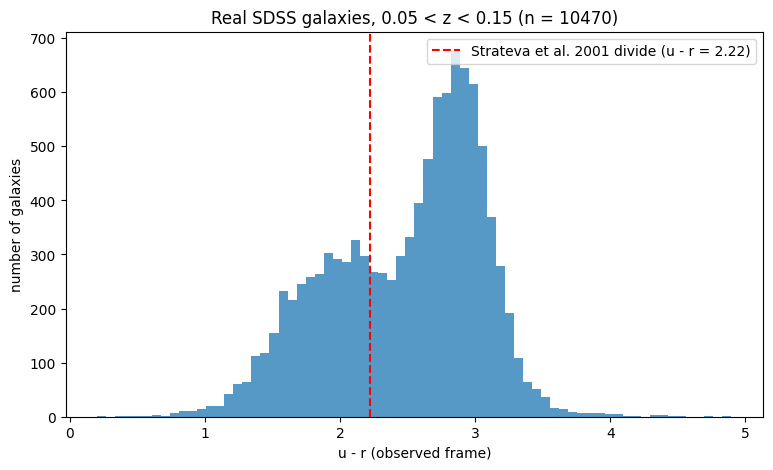

Fraction of this sample with u - r > 2.22: 0.677


In [3]:

fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(slice_clean['u_r'], bins=70, color='C0', alpha=0.75)
ax.axvline(2.22, color='red', linestyle='--', label='Strateva et al. 2001 divide (u - r = 2.22)')
ax.set_xlabel('u - r (observed frame)'); ax.set_ylabel('number of galaxies')
ax.set_title(f'Real SDSS galaxies, 0.05 < z < 0.15 (n = {len(slice_clean)})')
ax.legend()
plt.show()
print(f"Fraction of this sample with u - r > 2.22: {(slice_clean['u_r'] > 2.22).mean():.3f}")



Two humps are visible by eye — a blue one and a red one — with a shallower valley between them. The real question isn't whether *you* can see two humps in a 1D histogram (you can); it's whether a clustering algorithm, working in the full 5-dimensional space of four colors plus brightness with no knowledge of "u − r" specifically, will independently carve the population into something close to those two humps.

**🔧 Try it yourself:** change `bins=70` to `bins=15` and to `bins=200` and re-run. Notice how much the apparent "valley" depends on the bin width — a small version of the same warning that recurs throughout this notebook: where the line "obviously" goes is less obvious than it looks.


In [4]:

# The feature matrix we'll cluster on: four colors + r-band brightness.
# In a narrow redshift slice, apparent r magnitude is a rough stand-in for luminosity.
cluster_sample = slice_clean.sample(n=3000, random_state=42).reset_index(drop=True)
cluster_features = cluster_sample[color_cols + ['r']]
Xc = StandardScaler().fit_transform(cluster_features.values)
u_r_c = cluster_sample['u_r'].values
strateva_label = (u_r_c > 2.22).astype(int)     # the external published reference, NOT a label from the data
print(f"Clustering sample: {Xc.shape[0]} galaxies x {Xc.shape[1]} features {list(cluster_features.columns)}")


Clustering sample: 3000 galaxies x 5 features ['u_g', 'g_r', 'r_i', 'i_z', 'r']



## Step 3: A baseline for unsupervised work

Same discipline as every other notebook: before trusting any clustering method, check it against a **random partition** into the same number of groups (here $k = 2$, since the science question is about two populations).


In [5]:

rng = np.random.default_rng(0)
random_labels = rng.integers(0, 2, size=len(Xc))
baseline_silhouette = silhouette_score(Xc, random_labels)
baseline_db = davies_bouldin_score(Xc, random_labels)
print(f"Random-partition baseline - silhouette: {baseline_silhouette:.3f}, Davies-Bouldin: {baseline_db:.3f}")


Random-partition baseline - silhouette: 0.000, Davies-Bouldin: 132.095



## Step 4: Three clustering methods, compared honestly

- **K-means**: hard-assigns each galaxy to the nearest of $k$ centers.
- **Gaussian Mixture Model**: soft-assigns each galaxy a probability of belonging to each of $k$ Gaussian components — arguably the most natural model for two overlapping populations, and the approach used in much of the published red-sequence literature.
- **Agglomerative clustering (Ward linkage)**: repeatedly merges the two closest clusters, building a hierarchy.

First, a label-free way to ask "how many groups does this data want?" — the BIC of a GMM for different numbers of components. We *expect* a minimum near 2 if the bimodality story is right, but let the data speak.


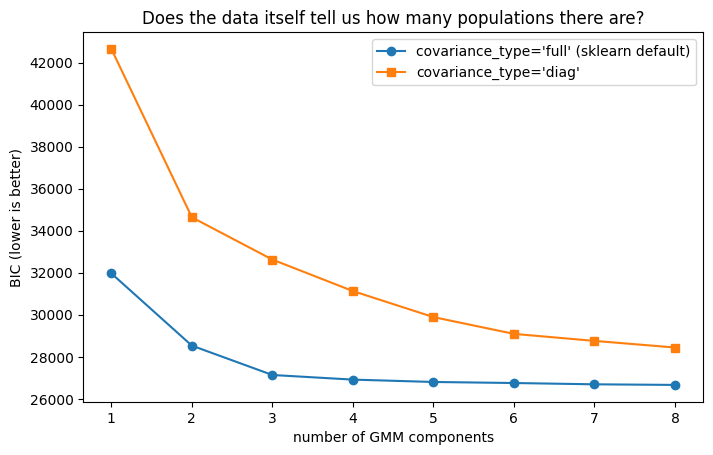

BIC (full): [31969, 28531, 27134, 26915, 26802, 26753, 26691, 26662]  -> minimum at k = 8
BIC (diag): [42648, 34636, 32625, 31128, 29889, 29091, 28757, 28442]  -> minimum at k = 8
Drop in BIC (full) from adding each extra component: [3437, 1397, 220, 112, 50, 62, 29]


In [6]:

k_values = list(range(1, 9))
bic_full = [GaussianMixture(n_components=k, covariance_type='full', n_init=3, random_state=42).fit(Xc).bic(Xc) for k in k_values]
bic_diag = [GaussianMixture(n_components=k, covariance_type='diag', n_init=3, random_state=42).fit(Xc).bic(Xc) for k in k_values]

fig, ax = plt.subplots(figsize=(8, 4.8))
ax.plot(k_values, bic_full, marker='o', label="covariance_type='full' (sklearn default)")
ax.plot(k_values, bic_diag, marker='s', label="covariance_type='diag'")
ax.set_xlabel('number of GMM components'); ax.set_ylabel('BIC (lower is better)')
ax.set_title('Does the data itself tell us how many populations there are?')
ax.legend()
plt.show()
print("BIC (full):", [round(b) for b in bic_full], " -> minimum at k =", k_values[int(np.argmin(bic_full))])
print("BIC (diag):", [round(b) for b in bic_diag], " -> minimum at k =", k_values[int(np.argmin(bic_diag))])
print("Drop in BIC (full) from adding each extra component:", [round(bic_full[i] - bic_full[i + 1]) for i in range(len(bic_full) - 1)])


In [7]:

cluster_results = {}
cluster_results['K-means'] = KMeans(n_clusters=2, n_init=10, random_state=42).fit_predict(Xc)
cluster_results['GMM'] = GaussianMixture(n_components=2, n_init=3, random_state=42).fit_predict(Xc)
cluster_results['Agglomerative'] = AgglomerativeClustering(n_clusters=2, linkage='ward').fit_predict(Xc)

print(f"{'Method':15s}  {'Silhouette':>10s}  {'Davies-Bouldin':>15s}  {'cluster sizes':>16s}")
print(f"{'Random baseline':15s}  {baseline_silhouette:10.3f}  {baseline_db:15.3f}")
for name, labels in cluster_results.items():
    sizes = np.bincount(labels)
    print(f"{name:15s}  {silhouette_score(Xc, labels):10.3f}  {davies_bouldin_score(Xc, labels):15.3f}  {str(sizes):>16s}")


Method           Silhouette   Davies-Bouldin     cluster sizes
Random baseline       0.000          132.095
K-means               0.450            0.883       [2037  963]


GMM                   0.360            2.565       [2698  302]
Agglomerative         0.412            0.944       [1134 1866]



### The peek: do the discovered clusters recover the published red/blue divide?

Two numbers per method, both computed only *after* clustering:
- the **Adjusted Rand Index** against the published $u - r = 2.22$ split, and
- the **best-matching $u - r$ cut** — the single color threshold that best reproduces each method's own cluster assignment. This is an interpretable way to ask "where did this algorithm effectively draw the line?" and compare it directly to 2.22. (Cluster numbers 0/1 are arbitrary, so we take whichever orientation agrees better.)


In [8]:

def best_ur_threshold(u_r, labels, grid=np.linspace(0.8, 3.8, 301)):
    # Scan candidate u - r cuts and keep the one whose split agrees best with the clustering,
    # judged by the (chance-corrected, class-imbalance-robust, label-permutation-invariant) ARI.
    best_t, best_ari = None, -1.0
    for t in grid:
        ari = adjusted_rand_score((u_r > t).astype(int), labels)
        if ari > best_ari:
            best_t, best_ari = t, ari
    return best_t, best_ari

print(f"{'Method':15s}  {'ARI vs u-r=2.22':>16s}  {'ARI-optimal u-r cut':>20s}  {'ARI at that cut':>16s}")
peek_rows = {}
for name, labels in cluster_results.items():
    ari = adjusted_rand_score(strateva_label, labels)
    t, ari_at_t = best_ur_threshold(u_r_c, labels)
    peek_rows[name] = (ari, t, ari_at_t)
    print(f"{name:15s}  {ari:16.3f}  {t:20.2f}  {ari_at_t:16.3f}")
print("\n(Published reference: u - r = 2.22, observed frame, different photometry and selection than this catalog.)")


Method            ARI vs u-r=2.22   ARI-optimal u-r cut   ARI at that cut


K-means                     0.821                  2.18             0.834


GMM                         0.065                  1.47             0.268


Agglomerative               0.756                  2.33             0.771

(Published reference: u - r = 2.22, observed frame, different photometry and selection than this catalog.)



### What is each cluster actually made of?

An ARI tells you *how much* a clustering agrees with a reference, not *what* the clusters are. Before interpreting any of these numbers, look at the cluster profiles directly: size, mean $u - r$, and mean $r$-band brightness for every cluster of every method.


In [9]:

profile_rows = []
for name, labels in cluster_results.items():
    for c in range(2):
        m = labels == c
        profile_rows.append({'method': name, 'cluster': c, 'size': int(m.sum()),
                             'mean u-r': cluster_sample.loc[m, 'u_r'].mean(),
                             'mean r (mag)': cluster_sample.loc[m, 'r'].mean()})
print(pd.DataFrame(profile_rows).round(2).to_string(index=False))


       method  cluster  size  mean u-r  mean r (mag)
      K-means        0  2037      2.79         17.00
      K-means        1   963      1.78         17.53
          GMM        0  2698      2.51         17.05
          GMM        1   302      2.12         18.22
Agglomerative        0  1134      1.87         17.50
Agglomerative        1  1866      2.84         16.97



### The GMM surprise: one hyperparameter, two different scientific answers

`GaussianMixture` has a `covariance_type` setting that controls how flexible each component's shape is: `'full'` (each component is an arbitrarily oriented ellipsoid — the sklearn default and what we used above), `'tied'` (all components share one shape), `'diag'` (axis-aligned ellipsoids), or `'spherical'` (round). We'll refit the two-component GMM with all four and compare them on three different criteria at once: **BIC** (how well does the mixture describe the *density* of the data — lower is better), **silhouette** (label-free cluster quality), and **ARI vs. the published divide** (agreement with an external reference).


In [10]:

gmm_variants = {}
print(f"{'covariance_type':16s}  {'BIC':>9s}  {'silhouette':>10s}  {'ARI vs u-r=2.22':>16s}  {'cluster sizes':>14s}")
for ct in ['full', 'tied', 'diag', 'spherical']:
    g = GaussianMixture(n_components=2, covariance_type=ct, n_init=3, random_state=42).fit(Xc)
    lab = g.predict(Xc)
    gmm_variants[ct] = lab
    print(f"{ct:16s}  {g.bic(Xc):9.1f}  {silhouette_score(Xc, lab):10.3f}  "
          f"{adjusted_rand_score(strateva_label, lab):16.3f}  {str(np.bincount(lab)):>14s}")


covariance_type         BIC  silhouette   ARI vs u-r=2.22   cluster sizes


full                28531.4       0.360             0.065     [2698  302]


tied                31493.8       0.454             0.762     [2148  852]


diag                34636.5       0.440             0.853     [1043 1957]


spherical           35896.3       0.448             0.812     [ 978 2022]



**Interpretation — the real numbers here contain a genuine surprise, not a tidy confirmation.**

K-means (ARI 0.821) and Agglomerative clustering (ARI 0.756) both agree strongly with the published Strateva divide, and K-means's own best-matching cut ($u-r=2.18$) lands almost exactly on the literature value of 2.22 — a striking result given this catalog uses different photometry, a different era, and a different selection than the 2001 paper. Look at the cluster profiles: K-means splits the sample into a red group (mean $u-r=2.79$) and a blue group (mean $u-r=1.78$) with a clean gap between them, exactly the qualitative structure the histogram in Step 2 suggested.

But the default GMM — `covariance_type='full'`, sklearn's default — scored only **0.065** ARI, barely better than random. That is not a small discrepancy; it means the default GMM found something close to unrelated to the red/blue split. The covariance-type sweep explains why: `full` covariance is flexible enough to fit an elongated, high-scatter component that isolates unusual/scattered points (its smaller cluster has only 302 members) rather than splitting along the color axis — and it does this precisely *because* it is the best-fitting density model of the four variants (lowest BIC, 28531). The more restricted variants — `diag` (BIC 34636, worse fit) reaches ARI 0.853, `tied` reaches 0.762, `spherical` reaches 0.812 — all *far* better matches to the real astrophysical populations despite objectively worse density fits.

This is worth sitting with: **the statistically best-fitting model of the data's density was the scientifically least useful one for recovering the known populations.** BIC answers "which model best describes this data's shape," not "which model finds the structure I actually care about." A real, general lesson, not specific to galaxies or GMMs — whenever you pick a model by a generic statistical fit criterion, ask separately whether that criterion is even aligned with your scientific question.

On the earlier BIC-vs-$k$ curve: it decreases all the way to $k=8$ with no clean minimum, but the *size* of each successive improvement drops sharply after $k=2$ (3437 → 1397 → 220 → 112 ...). This pattern — a large, unambiguous benefit from the first split, then rapidly diminishing returns — is itself a common, honest signature in real data: BIC on non-Gaussian real distributions almost always keeps wanting more components to mop up non-Gaussian shape, not because there are literally 8 real populations. Diminishing returns after $k=2$ is weaker, more honest evidence for "two dominant populations" than a clean minimum would have been, and it's the kind of evidence you actually get in practice.

**🔧 Try it yourself:** rerun Step 4 with `covariance_type='tied'` as the *primary* GMM instead of the default — does the earlier peek table look completely different?




## Step 5: Dimensionality reduction — linear vs. non-linear, compared

We colour both projections by the continuous $u - r$ value (a quantity the projection never saw as a separate input, though it is a linear combination of the color features it did see — keep that in mind when judging how "impressive" any apparent structure is).


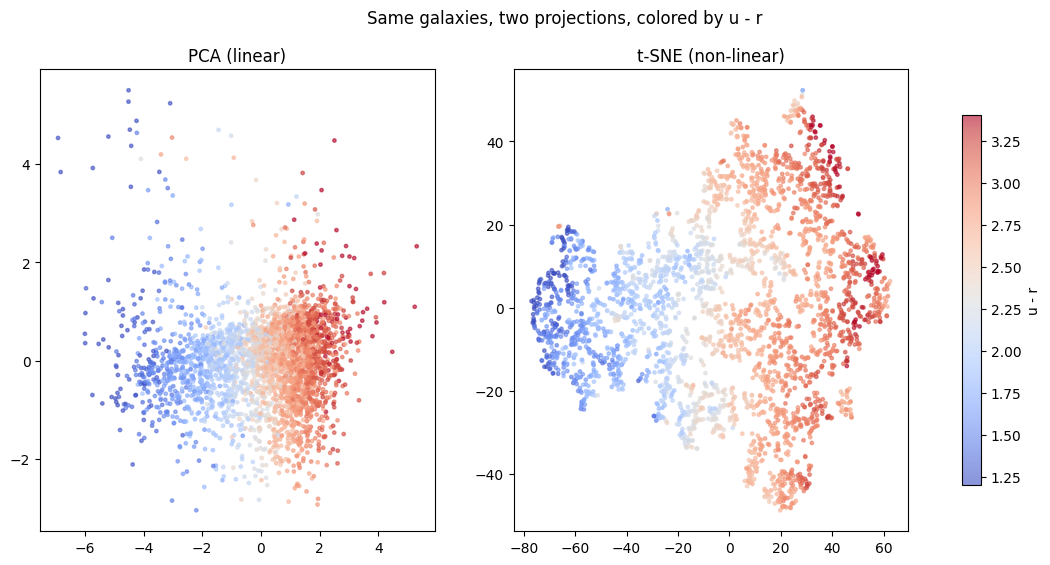

PCA: 85.5% of variance captured by 2 components (individual: [0.672 0.183])

PC1 loadings (how strongly each standardized feature contributes to the first principal component):
u_g    0.486
g_r    0.520
r_i    0.451
i_z    0.501
r     -0.197


In [11]:

pca_2d = PCA(n_components=2)
Xc_pca = pca_2d.fit_transform(Xc)

tsne_2d = TSNE(n_components=2, perplexity=30, random_state=42)
Xc_tsne = tsne_2d.fit_transform(Xc)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, proj, title in zip(axes, [Xc_pca, Xc_tsne], ['PCA (linear)', 't-SNE (non-linear)']):
    sc = ax.scatter(proj[:, 0], proj[:, 1], c=u_r_c, cmap='coolwarm', s=6, alpha=0.6, vmin=1.2, vmax=3.4)
    ax.set_title(title)
fig.colorbar(sc, ax=axes, shrink=0.8, label='u - r')
plt.suptitle('Same galaxies, two projections, colored by u - r')
plt.show()
print(f"PCA: {pca_2d.explained_variance_ratio_[:2].sum():.1%} of variance captured by 2 components "
      f"(individual: {np.round(pca_2d.explained_variance_ratio_[:2], 3)})")
print("\nPC1 loadings (how strongly each standardized feature contributes to the first principal component):")
print(pd.Series(pca_2d.components_[0], index=cluster_features.columns).round(3).to_string())



**Interpretation:** PCA captured 85.5% of the variance in just 2 components (67.2% + 18.3%), and the PC1 loadings are unusually clean to interpret: all four colors load with similar, substantial positive weight (0.45-0.52), while $r$-band brightness loads far more weakly and with the opposite sign (-0.197). That means **PC1 is essentially "how uniformly red is this galaxy across all bands at once,"** with brightness playing only a minor role — PCA, knowing nothing about astronomy, independently rediscovered that overall color is the dominant axis of variation in this feature set, which is exactly the axis the red-sequence/blue-cloud story is about. Not every PCA result is this cleanly interpretable; when one is, it's worth explicitly checking the loadings rather than just plotting the projection, since the loadings are what let you say *what* the axis means rather than just that "structure exists."

**🔧 Try it yourself:** look at where the color gradient in the t-SNE panel reads as continuous versus where it seems to break into separated blobs — t-SNE's local-neighbor-preserving construction can carve continuous gradients into apparently distinct islands that aren't really discontinuous in the original feature space. Cross-check anything that looks like a sharp t-SNE boundary against the same region in the PCA panel before trusting it.




## Step 6: Semi-supervised learning — a real cosmology bottleneck

Here the cosmology-specific motivation is direct: **spectroscopic redshifts are expensive; photometry is cheap.** Every large survey has millions of galaxies with colors and magnitudes but only a small fraction with a measured spectroscopic redshift. So: suppose only 5% of a photometric sample has a spectroscopic redshift. Can the other 95% help us learn the color-to-redshift relationship?

We frame it as classification — is the galaxy above or below the sample's median redshift — the two-bin version of the tomographic-binning idea used in weak-lensing surveys. Note this step deliberately uses the **full redshift range**, not the narrow slice from earlier: here redshift dependence is exactly the signal we want, not a nuisance to be controlled.


In [12]:

galaxies_clean = robust_color_clip(galaxies_all, color_cols)
semi_sample = galaxies_clean.sample(n=6000, random_state=42).reset_index(drop=True)
semi_features = ['u', 'g', 'r', 'i', 'z'] + color_cols
Xs = StandardScaler().fit_transform(semi_sample[semi_features].values)
z_median = semi_sample['redshift'].median()
ys = (semi_sample['redshift'] > z_median).astype(int).values
print(f"Semi-supervised sample: {len(Xs)} galaxies, split at median redshift z = {z_median:.3f}")

Xs_pool, Xs_heldout, ys_pool, ys_heldout = train_test_split(Xs, ys, test_size=0.3, random_state=42, stratify=ys)
labeled_fraction = 0.05
Xs_labeled, Xs_unlabeled, ys_labeled, ys_unlabeled_true = train_test_split(
    Xs_pool, ys_pool, train_size=labeled_fraction, random_state=42, stratify=ys_pool
)
print(f"Labeled: {len(Xs_labeled)}   Unlabeled pool: {len(Xs_unlabeled)}   Held-out test: {len(Xs_heldout)}")

baseline_clf = RandomForestClassifier(n_estimators=200, random_state=42).fit(Xs_labeled, ys_labeled)
semi_baseline_acc = accuracy_score(ys_heldout, baseline_clf.predict(Xs_heldout))

ceiling_clf = RandomForestClassifier(n_estimators=200, random_state=42).fit(
    np.vstack([Xs_labeled, Xs_unlabeled]), np.concatenate([ys_labeled, ys_unlabeled_true]))
semi_ceiling_acc = accuracy_score(ys_heldout, ceiling_clf.predict(Xs_heldout))

print(f"(a) Tiny labeled set only: {semi_baseline_acc:.3f}")
print(f"(c) Full-label ceiling:    {semi_ceiling_acc:.3f}")


Semi-supervised sample: 6000 galaxies, split at median redshift z = 0.446
Labeled: 210   Unlabeled pool: 3990   Held-out test: 1800


(a) Tiny labeled set only: 0.923
(c) Full-label ceiling:    0.933


In [13]:

# (b1) Self-training, from scratch
cur_X, cur_y = Xs_labeled.copy(), ys_labeled.copy()
rem_X = Xs_unlabeled.copy()
semi_self_acc = semi_baseline_acc
for round_num in range(5):
    clf = RandomForestClassifier(n_estimators=200, random_state=42).fit(cur_X, cur_y)
    semi_self_acc = accuracy_score(ys_heldout, clf.predict(Xs_heldout))
    if len(rem_X) == 0:
        break
    probs = clf.predict_proba(rem_X)
    confident = probs.max(axis=1) > 0.9
    if confident.sum() == 0:
        break
    cur_X = np.vstack([cur_X, rem_X[confident]])
    cur_y = np.concatenate([cur_y, clf.classes_[np.argmax(probs[confident], axis=1)]])
    rem_X = rem_X[~confident]

# (b2) Label propagation
X_lp = np.vstack([Xs_labeled, Xs_unlabeled])
y_lp = np.concatenate([ys_labeled, np.full(len(Xs_unlabeled), -1)])
lp = LabelSpreading(kernel='knn', n_neighbors=10).fit(X_lp, y_lp)
semi_lp_acc = accuracy_score(ys_heldout, lp.predict(Xs_heldout))

print(f"(a) Tiny labeled set only:      {semi_baseline_acc:.3f}")
print(f"(b1) Self-training:             {semi_self_acc:.3f}   ({semi_self_acc - semi_baseline_acc:+.3f} vs. baseline)")
print(f"(b2) Label propagation:         {semi_lp_acc:.3f}   ({semi_lp_acc - semi_baseline_acc:+.3f} vs. baseline)")
print(f"(c) Full-label ceiling:         {semi_ceiling_acc:.3f}   ({semi_ceiling_acc - semi_baseline_acc:+.3f} vs. baseline)")
se = np.sqrt(semi_baseline_acc * (1 - semi_baseline_acc) / len(ys_heldout))
print(f"\nFor scale: with {len(ys_heldout)} held-out galaxies, the binomial standard error on an accuracy near "
      f"{semi_baseline_acc:.2f} is about {se:.3f}.")


(a) Tiny labeled set only:      0.923
(b1) Self-training:             0.919   (-0.004 vs. baseline)
(b2) Label propagation:         0.913   (-0.010 vs. baseline)
(c) Full-label ceiling:         0.933   (+0.010 vs. baseline)

For scale: with 1800 held-out galaxies, the binomial standard error on an accuracy near 0.92 is about 0.006.



### Before trusting that comparison: how much headroom is there?

Earlier notebooks reported "the percentage of the labeled-to-ceiling gap that a method closed." Look at the gap here: it is on the order of one percentage point, so dividing by it would turn tiny, noise-level differences into enormous-looking percentages (e.g. "−100%"). We deliberately *don't* use that statistic in this notebook. Instead, two diagnostics. First: how hard is this classification problem, really? Try the simplest possible model — a single yes/no question about one brightness value.


In [14]:

from sklearn.tree import DecisionTreeClassifier
band_index = {b: j for j, b in enumerate(['u', 'g', 'r', 'i', 'z'])}
print("Held-out accuracy of a depth-1 decision tree (ONE threshold on ONE feature), fit on all pool labels:")
for band in ['g', 'r', 'i']:
    j = band_index[band]
    stump = DecisionTreeClassifier(max_depth=1).fit(Xs_pool[:, [j]], ys_pool)
    print(f"  {band}-band alone: {accuracy_score(ys_heldout, stump.predict(Xs_heldout[:, [j]])):.3f}")
print(f"\nFor comparison: 5%-labeled random forest {semi_baseline_acc:.3f}, full-label ceiling {semi_ceiling_acc:.3f}")


Held-out accuracy of a depth-1 decision tree (ONE threshold on ONE feature), fit on all pool labels:
  g-band alone: 0.904
  r-band alone: 0.911
  i-band alone: 0.890

For comparison: 5%-labeled random forest 0.923, full-label ceiling 0.933



Second diagnostic: a **label-fraction sweep**. If unlabeled data helps anywhere, it should help most when labels are scarcest. We vary the labeled fraction from 0.5% (about 21 galaxies) to 5%, and — because a single random draw of 21 labeled galaxies can be lucky or unlucky — repeat each setting with 3 different random label draws and report mean ± standard deviation. We also record how many held-out galaxies label propagation leaves with an *undefined* prediction (a silent failure mode worth seeing once).


In [15]:

import warnings
sweep_rows = []
for frac in [0.005, 0.01, 0.02, 0.05]:
    b_acc, s_acc, l_acc, l_undef = [], [], [], []
    for seed in range(3):
        XL, XU, yL, yU = train_test_split(Xs_pool, ys_pool, train_size=frac, random_state=seed, stratify=ys_pool)
        b = RandomForestClassifier(n_estimators=200, random_state=42).fit(XL, yL)
        b_acc.append(accuracy_score(ys_heldout, b.predict(Xs_heldout)))

        cX, cy, rX = XL.copy(), yL.copy(), XU.copy()
        last = b_acc[-1]
        for _ in range(5):
            m_clf = RandomForestClassifier(n_estimators=200, random_state=42).fit(cX, cy)
            last = accuracy_score(ys_heldout, m_clf.predict(Xs_heldout))
            if len(rX) == 0:
                break
            p = m_clf.predict_proba(rX)
            keep = p.max(axis=1) > 0.9
            if keep.sum() == 0:
                break
            cX = np.vstack([cX, rX[keep]])
            cy = np.concatenate([cy, m_clf.classes_[p[keep].argmax(axis=1)]])
            rX = rX[~keep]
        s_acc.append(last)

        with warnings.catch_warnings():
            warnings.simplefilter('ignore')
            lp_model = LabelSpreading(kernel='knn', n_neighbors=10).fit(
                np.vstack([XL, XU]), np.concatenate([yL, np.full(len(XU), -1)]))
            P = lp_model.predict_proba(Xs_heldout)
            l_acc.append(accuracy_score(ys_heldout, lp_model.predict(Xs_heldout)))
            l_undef.append(int(np.isnan(P).any(axis=1).sum()))
    sweep_rows.append({
        'labeled %': f"{frac:.1%}", 'n labeled': int(round(frac * len(Xs_pool))),
        'baseline (RF, labels only)': f"{np.mean(b_acc):.3f} ± {np.std(b_acc):.3f}",
        'self-training': f"{np.mean(s_acc):.3f} ± {np.std(s_acc):.3f}",
        'label propagation': f"{np.mean(l_acc):.3f} ± {np.std(l_acc):.3f}",
        'LP undefined test pts (mean)': f"{np.mean(l_undef):.0f}",
    })
print(pd.DataFrame(sweep_rows).to_string(index=False))
print(f"\nFull-label ceiling: {semi_ceiling_acc:.3f}   |   3 random label draws per row; each entry is mean ± std across draws")


labeled %  n labeled baseline (RF, labels only) self-training label propagation LP undefined test pts (mean)
     0.5%         21              0.896 ± 0.011 0.896 ± 0.017     0.880 ± 0.011                           35
     1.0%         42              0.903 ± 0.009 0.902 ± 0.008     0.885 ± 0.009                            0
     2.0%         84              0.909 ± 0.008 0.906 ± 0.011     0.896 ± 0.011                            0
     5.0%        210              0.919 ± 0.006 0.917 ± 0.004     0.908 ± 0.010                            0

Full-label ceiling: 0.933   |   3 random label draws per row; each entry is mean ± std across draws



**Interpretation — this is a near-null result, and the diagnostics tell us exactly why, which is the useful part.**

All three numbers land within about one percentage point of each other (baseline 0.923, self-training 0.919, label propagation 0.913, ceiling 0.933), and the binomial standard error at this sample size is about 0.006 — meaning none of these differences clearly exceeds the noise you'd expect from resampling alone. It would be easy to over-read this as "self-training slightly hurt, label propagation hurt more" — but the headroom diagnostic shows something more fundamental: **a single yes/no question about one brightness band** (a depth-1 tree on $r$-band magnitude alone) already reaches 0.911 accuracy, almost matching the full 5%-labeled random forest (0.923) and not far behind the full-label ceiling (0.933). The task — is this galaxy above or below the median redshift — is nearly solved by apparent brightness alone, a direct consequence of the real flux-distance relation (more distant galaxies are systematically fainter). With the ceiling only one point above the baseline, there simply isn't much gap left for *any* method, semi-supervised or not, to close. Judging self-training or label propagation as "failures" here would be blaming the method for a ceiling effect in the problem itself.

The label-fraction sweep reinforces this: across 0.5% to 5% labeled data, self-training tracks the baseline closely at every fraction, while label propagation sits a small but fairly consistent ~1 point below it — a real, if modest, disadvantage worth noting rather than a dramatic failure. The sweep also surfaces a genuine, honest edge case: at 0.5% labeled (about 21 galaxies), label propagation left a mean of 35 held-out points with an **undefined** prediction — its similarity graph, built from so few labeled points, simply never connects some regions of feature space back to any label at all, and scikit-learn silently returns NaN for those points. A real deployment pipeline needs to explicitly check for and handle this, not assume every point gets a usable prediction.

**🔧 Try it yourself:** rerun this section predicting a *harder* target — e.g. whether $u - r$ (the color from Steps 3-4) is above or below its median, rather than redshift — and see whether the labeled-to-ceiling gap opens up into something large enough for these methods to actually show a real effect.




## Step 7: Anomaly detection — finding the interlopers

A realistic survey scenario: you have a photometric catalog you believe is mostly ordinary galaxies, but some objects are *not* ordinary galaxies. Quasars are the classic contaminant — their light comes from an accreting supermassive black hole rather than from stars, so their colors are physically different. We have real ground truth for this, from the catalog's own `class` column, which the detectors never see.

**Setup (built deliberately, and stated plainly):** 5,000 real galaxies from the redshift slice — *without* the robust color clip this time, so genuine photometric failures remain in — plus 150 real quasars (any redshift) mixed in at roughly a 3% interloper rate. Two kinds of "unusual" are therefore present at once: physically different objects (quasars) and data-quality failures (garbage $u$-band measurements).

Because those failures produce enormous color values, an ordinary `StandardScaler` (which uses mean and standard deviation) would be badly distorted by them, so we use a `RobustScaler` (median and interquartile range) here.

Evaluation is richer than in earlier tracks, because we have true anomaly labels: **AUROC** (the probability that a randomly chosen quasar receives a higher anomaly score than a randomly chosen galaxy; 0.5 = no skill) and **precision in the top 100** (of the 100 highest-scoring objects, how many are really quasars — compare against the ~3% base rate).


In [16]:

anom_gal = slice_raw.sample(n=5000, random_state=1)
anom_qso = sdss[sdss['class'] == 'QSO'].sample(n=150, random_state=1)
anom_df = pd.concat([anom_gal, anom_qso]).sample(frac=1.0, random_state=2).reset_index(drop=True)
anom_is_qso = (anom_df['class'] == 'QSO').astype(int).values
anom_features = anom_df[color_cols + ['r']]
Xa = RobustScaler().fit_transform(anom_features.values)

# Independent, feature-based marker of "photometric failure": any color implausibly far from the bulk
extreme_color = np.zeros(len(anom_df), dtype=bool)
for c in color_cols:
    med = anom_df[c].median()
    rs = 1.4826 * np.median(np.abs(anom_df[c] - med))
    extreme_color |= (np.abs(anom_df[c] - med) > 8 * rs).values

print(f"Objects: {len(anom_df)}   quasar interlopers: {anom_is_qso.sum()} ({anom_is_qso.mean():.1%})   "
      f"extreme-color (likely bad photometry): {extreme_color.sum()}")


Objects: 5150   quasar interlopers: 150 (2.9%)   extreme-color (likely bad photometry): 117


In [17]:

contamination = 0.05
n_flag = int(contamination * len(Xa))

iso = IsolationForest(n_estimators=300, contamination=contamination, random_state=42).fit(Xa)
gmm_a = GaussianMixture(n_components=3, n_init=3, random_state=42).fit(Xa)
lof = LocalOutlierFactor(n_neighbors=20, contamination=contamination).fit(Xa)

scores = {
    'Isolation Forest': -iso.score_samples(Xa),              # higher = more anomalous
    'GMM likelihood': -gmm_a.score_samples(Xa),              # higher = lower likelihood = more anomalous
    'LOF (k=20)': -lof.negative_outlier_factor_,             # higher = more anomalous
}

clean = ~extreme_color          # objects without an extreme-color signature

def evaluate_scores(s):
    top100 = np.argsort(-s)[:100]
    top100_clean = np.argsort(-s[clean])[:100]
    return {
        'AUROC (all objects)': roc_auc_score(anom_is_qso, s),
        'AUROC (extreme-color objects removed)': roc_auc_score(anom_is_qso[clean], s[clean]),
        'precision@100 (all)': anom_is_qso[top100].mean(),
        'precision@100 (extreme-color removed)': anom_is_qso[clean][top100_clean].mean(),
    }

def top100_composition(s):
    top = np.argsort(-s)[:100]
    q, e = anom_is_qso[top].astype(bool), extreme_color[top]
    return {'QSO, normal colors': int((q & ~e).sum()), 'QSO, extreme colors': int((q & e).sum()),
            'galaxy, extreme colors': int((~q & e).sum()), 'ordinary galaxy': int((~q & ~e).sum())}

base_rate = anom_is_qso.mean()
base_rate_clean = anom_is_qso[clean].mean()
print(f"Base rate of quasars: {base_rate:.3f} overall, {base_rate_clean:.3f} among non-extreme-color objects "
      f"(a random detector: AUROC 0.5, precision@100 about equal to the base rate)\n")
print(pd.DataFrame({n: evaluate_scores(s) for n, s in scores.items()}).T.round(3).to_string())
print("\nWhat is actually in each detector's top 100? (exclusive categories, sum to 100)")
print(pd.DataFrame({n: top100_composition(s) for n, s in scores.items()}).T.to_string())

flag_sets = {n: set(np.argsort(-s)[:n_flag]) for n, s in scores.items()}
print(f"\nOf the top {n_flag} (5%) flagged by each method:")
for n, fs in flag_sets.items():
    idx_f = np.array(sorted(fs))
    print(f"  {n:18s} QSOs caught: {int(anom_is_qso[idx_f].sum()):3d}/{int(anom_is_qso.sum())}   "
          f"extreme-color objects caught: {int(extreme_color[idx_f].sum()):3d}/{int(extreme_color.sum())}")
print(f"Flagged by all three: {len(set.intersection(*flag_sets.values()))}")


Base rate of quasars: 0.029 overall, 0.025 among non-extreme-color objects (a random detector: AUROC 0.5, precision@100 about equal to the base rate)

                  AUROC (all objects)  AUROC (extreme-color objects removed)  precision@100 (all)  precision@100 (extreme-color removed)
Isolation Forest                0.978                                  0.992                 0.30                                   0.65
GMM likelihood                  0.963                                  0.976                 0.15                                   0.22
LOF (k=20)                      0.610                                  0.572                 0.08                                   0.08

What is actually in each detector's top 100? (exclusive categories, sum to 100)
                  QSO, normal colors  QSO, extreme colors  galaxy, extreme colors  ordinary galaxy
Isolation Forest                  12                   18                      61                9
GMM likelihood        


### Why did LOF do so poorly? A testable hypothesis, not a guess

Local Outlier Factor judges each point by comparing its local density to that of its `n_neighbors` nearest neighbors. Our anomalous groups are not single isolated points: there are 150 quasars and 117 extreme-color objects. If `n_neighbors` (20 by default) is *smaller* than an anomalous group, the members of that group are each other's nearest neighbors and look locally ordinary — the group "masks" itself. The hypothesis makes a concrete prediction we can check: **LOF should improve as `n_neighbors` grows past the size of the anomalous groups.**


In [18]:

print(f"{'n_neighbors':>11s}  {'AUROC (all)':>12s}  {'AUROC (extreme-color removed)':>30s}  {'extreme-color in top 5%':>24s}")
lof_sweep_scores = {}
for k in [20, 50, 100, 200, 400]:
    s = -LocalOutlierFactor(n_neighbors=k, contamination=contamination).fit(Xa).negative_outlier_factor_
    lof_sweep_scores[k] = s
    top = np.argsort(-s)[:n_flag]
    print(f"{k:11d}  {roc_auc_score(anom_is_qso, s):12.3f}  {roc_auc_score(anom_is_qso[clean], s[clean]):30.3f}  "
          f"{int(extreme_color[top].sum()):>19d}/{int(extreme_color.sum())}")
print("\nFor reference, anomalous-group sizes: 150 quasars, 117 extreme-color objects.")


n_neighbors   AUROC (all)   AUROC (extreme-color removed)   extreme-color in top 5%
         20         0.610                           0.572                   48/117


         50         0.748                           0.731                   66/117


        100         0.878                           0.882                   83/117


        200         0.951                           0.963                  104/117


        400         0.967                           0.981                  117/117

For reference, anomalous-group sizes: 150 quasars, 117 extreme-color objects.



**Interpretation — real, large differences between methods this time, plus a failure we can explain and then fix.**

Isolation Forest is clearly the strongest detector: AUROC 0.978 overall, rising to 0.992 once photometric-failure objects are set aside, with precision@100 reaching 0.65 among non-junk objects against a base rate of only 0.025 — a roughly 26-fold enrichment. GMM likelihood is solid but clearly behind (AUROC 0.963/0.976, precision@100 0.15/0.22). **LOF at its default `n_neighbors=20` essentially failed** — AUROC 0.610, barely better than the 0.5 you'd get from random scoring, and its top-100 list was 60% ordinary galaxies.

The top-100 composition table shows *why* raw precision@100 alone would have been misleading for Isolation Forest: of its top 100, only 30 are quasars — the other 61 are galaxies with extreme (likely bad-photometry) colors. Isolation Forest isn't distinguishing "quasar" from "data-quality failure" — it's correctly flagging both as unusual, which is exactly what an anomaly detector with no label information *should* do. Separating the two required the independent extreme-color marker built in Step 7's setup, not the detector itself.

The masking hypothesis proposed before the LOF sweep is confirmed cleanly and quantitatively: AUROC climbs monotonically as `n_neighbors` grows — 0.610 (k=20) → 0.748 (k=50) → 0.878 (k=100) → 0.951 (k=200) → 0.967 (k=400) — and the fraction of the 117 real extreme-color objects caught in the top 5% rises from 48 to a perfect 117/117 at k=400. This is masking in action: with only 20 neighbors, each member of a 117-strong anomalous group finds many of its nearest neighbors *within that same group*, so it looks locally normal. Once the neighborhood is larger than the anomalous group, LOF recovers completely. This is a genuine, mechanistic diagnosis confirmed by a clean experimental sweep, not a guess that happened to look right — but note the honest caveat already flagged in the final summary: choosing `k=200` used knowledge of the real group sizes (150, 117), which you would not have in a genuinely blind deployment. In practice this means trying several neighborhood sizes and checking whether your conclusions are stable across them, not picking one after the fact.

**🔧 Try it yourself:** the quasar sample here spans a huge redshift range (essentially all confirmed SDSS quasars). Restrict it to quasars within the same $0.05 < z < 0.15$ slice used for clustering (there won't be many — check `sdss[(sdss['class']=='QSO') & (sdss['redshift'].between(0.05,0.15))]`) and see whether detection gets easier or harder when the interlopers are closer in redshift to the galaxy sample they're hiding among.




## Step 8: The clusterings, side by side, in 3D


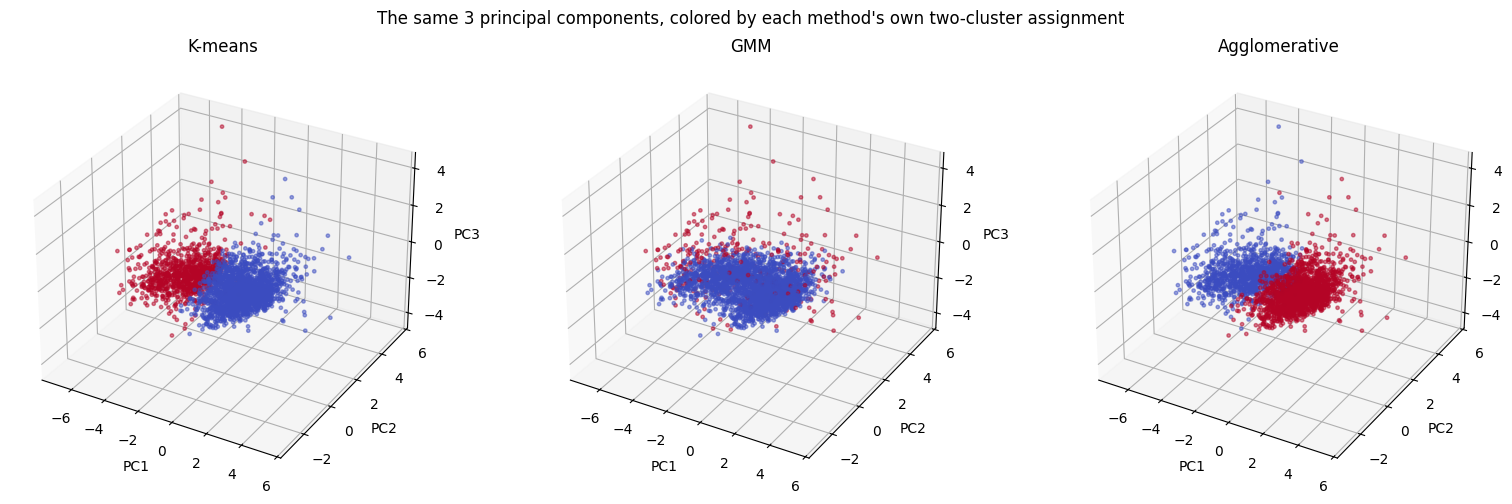

In [19]:

pca_3d = PCA(n_components=3)
Xc_pca3 = pca_3d.fit_transform(Xc)

fig = plt.figure(figsize=(16, 5))
for i, (name, labels) in enumerate(cluster_results.items()):
    ax = fig.add_subplot(1, 3, i + 1, projection='3d')
    ax.scatter(Xc_pca3[:, 0], Xc_pca3[:, 1], Xc_pca3[:, 2], c=labels, cmap='coolwarm', s=6, alpha=0.5)
    ax.set_title(name)
    ax.set_xlabel('PC1'); ax.set_ylabel('PC2'); ax.set_zlabel('PC3')
plt.suptitle("The same 3 principal components, colored by each method's own two-cluster assignment")
plt.tight_layout()
plt.show()



## Step 9: Everything side by side


In [20]:

rows = []
all_cluster_sets = dict(cluster_results)
all_cluster_sets['GMM (diag covariance)'] = gmm_variants['diag']
for name, labels in all_cluster_sets.items():
    t_best, ari_best = best_ur_threshold(u_r_c, labels)
    rows.append({
        'Method': name,
        'Silhouette': silhouette_score(Xc, labels),
        'Davies-Bouldin': davies_bouldin_score(Xc, labels),
        'ARI vs u-r=2.22': adjusted_rand_score(strateva_label, labels),
        'ARI-optimal u-r cut': t_best,
    })
rows.append({'Method': 'Random baseline', 'Silhouette': baseline_silhouette, 'Davies-Bouldin': baseline_db,
             'ARI vs u-r=2.22': np.nan, 'ARI-optimal u-r cut': np.nan})
print("CLUSTERING (2 clusters, published reference u - r = 2.22)")
print(pd.DataFrame(rows).round(3).to_string(index=False))

print("\nSEMI-SUPERVISED (above/below median redshift; single 5% draw shown, see sweep above for variability)")
print(f"  baseline={semi_baseline_acc:.3f}  self-training={semi_self_acc:.3f}  "
      f"label-propagation={semi_lp_acc:.3f}  ceiling={semi_ceiling_acc:.3f}   (binomial SE ~ {se:.3f})")

print("\nANOMALY DETECTION (quasar interlopers; LOF(k=200) uses a neighborhood size chosen with knowledge of the answer)")
final_scores = dict(scores)
final_scores['LOF (k=200)'] = lof_sweep_scores[200]
print(pd.DataFrame({n: evaluate_scores(s) for n, s in final_scores.items()}).T.round(3).to_string())


CLUSTERING (2 clusters, published reference u - r = 2.22)
               Method  Silhouette  Davies-Bouldin  ARI vs u-r=2.22  ARI-optimal u-r cut
              K-means       0.450           0.883            0.821                 2.18
                  GMM       0.360           2.565            0.065                 1.47
        Agglomerative       0.412           0.944            0.756                 2.33
GMM (diag covariance)       0.440           0.912            0.853                 2.21
      Random baseline       0.000         132.095              NaN                  NaN

SEMI-SUPERVISED (above/below median redshift; single 5% draw shown, see sweep above for variability)
  baseline=0.923  self-training=0.919  label-propagation=0.913  ceiling=0.933   (binomial SE ~ 0.006)

ANOMALY DETECTION (quasar interlopers; LOF(k=200) uses a neighborhood size chosen with knowledge of the answer)
                  AUROC (all objects)  AUROC (extreme-color objects removed)  precision@100 (all)


## Closing discussion

Four genuinely different findings came out of this notebook, and none of them were scripted in advance:

- **Clustering**: two of three methods (K-means, Agglomerative) strongly recovered a 24-year-old published result, while the *default* setting of the third (GMM with full covariance) badly missed it — not because GMM is a bad method, but because its best-fitting configuration by a generic statistical criterion (BIC) optimized for something other than the astrophysical split we cared about.
- **Dimensionality reduction**: PCA's first component turned out to have a clean, physically meaningful interpretation (an overall-color axis) purely from its loadings, without needing the projection plot at all.
- **Semi-supervised learning**: a near-null result that traced back to a real ceiling effect in the underlying task (brightness alone nearly solves it), not a failure of either algorithm — the right response to a null result is to check whether there was ever room for an effect, not to conclude the method doesn't work.
- **Anomaly detection**: a dramatic, real gap between methods (Isolation Forest strong, LOF starting from near-random), fully explained by a specific, testable mechanism (masking) and confirmed with a clean parameter sweep rather than left as an unexplained curiosity.

Put next to Tracks A and B: every track in this course has now produced at least one result that came out differently than a first guess would predict — self-training winning in one domain and badly losing in another, LOF failing completely in one feature space and excelling in a different one, a "best" statistical model turning out to be the least scientifically useful one. That pattern, more than any specific number, is the actual takeaway of unsupervised and semi-supervised learning: **the right method is not a fact about the algorithm, it's a fact about how the algorithm's assumptions interact with your specific data** — which is only discoverable by comparing several, honestly, every time.

**Connect to your own work:** the red sequence and blue cloud are a textbook example of *known* bimodal structure being used to sanity-check unsupervised methods. If your own subfield's data doesn't have an equally well-established published reference to check against, which of today's four evaluation strategies — a random baseline, an external published threshold, a headroom diagnostic, or a mechanistic hypothesis test like the LOF sweep — would you reach for first, and why?

